In [2]:
pip install opencv-python matplotlib 'numpy<2'

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [10]:
def add_gaussian_noise(image, mean=0, std=1):
    gaussian_noise = np.random.normal(mean, std, image.shape)
    noisy_image = image + gaussian_noise
    noisy_image = np.clip(noisy_image, 0, 255)
    return noisy_image.astype(np.uint8)

In [3]:
import numpy as np

def add_rayleigh_noise(image, scale=1):
    rayleigh_noise = np.random.rayleigh(scale, image.shape)
    noisy_image = image + rayleigh_noise
    noisy_image = np.clip(noisy_image, 0, 255)
    return noisy_image

In [4]:
def add_exponential_noise(image, scale=1):
    exponential_noise =np.random.exponential(scale, image.shape)
    noisy_image = image + exponential_noise
    noisy_image = np.clip(noisy_image, 0, 255)
    return noisy_image

In [5]:
def add_salt_pepper_noise(image, salt_prob=0.05,pepper_prob=0.05):
    noisy_image = image.copy()
    num_salt = np.ceil(salt_prob * image.size)
    coords = [np.random.randint(0, i - 1, int(num_salt)) for i in image.shape]
    noisy_image[coords[0], coords[1]] = 255
    num_pepper = np.ceil(pepper_prob * image.size)
    coords = [np.random.randint(0, i - 1, int(num_pepper)) for i in image.shape]
    noisy_image[coords[0], coords[1]] = 0
    return noisy_image

In [6]:
def add_uniform_noise(image, low=0, high=10):
    uniform_noise = np.random.uniform(low, high, image.shape)
    noisy_image = image + uniform_noise
    noisy_image = np.clip(noisy_image, 0, 255)
    return noisy_image
    

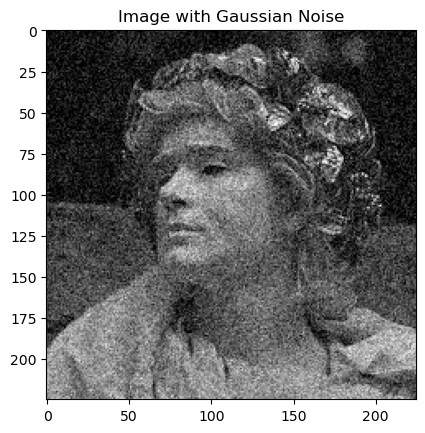

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread('/Users/230363/Downloads/images.jpeg',cv2.IMREAD_GRAYSCALE)

noisy_image = add_gaussian_noise(image, mean=0,std=20)

plt.imshow(noisy_image, cmap='gray')
plt.title("Image with Gaussian Noise")
plt.show()

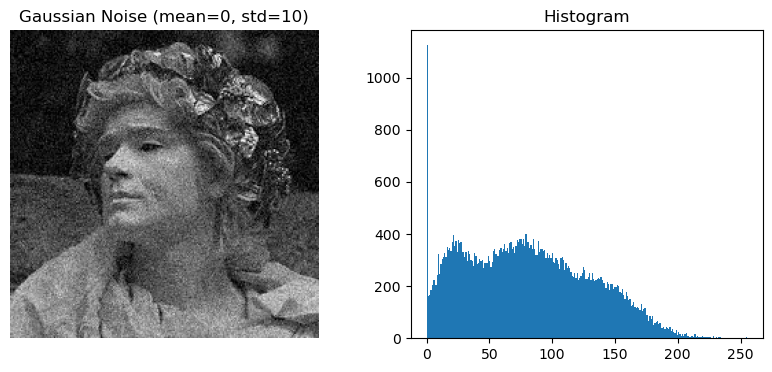

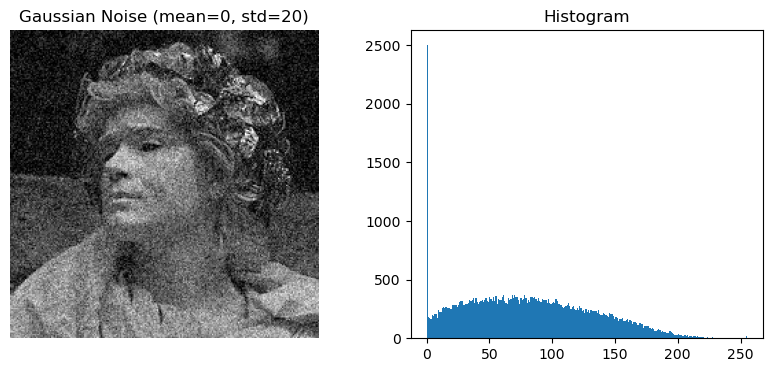

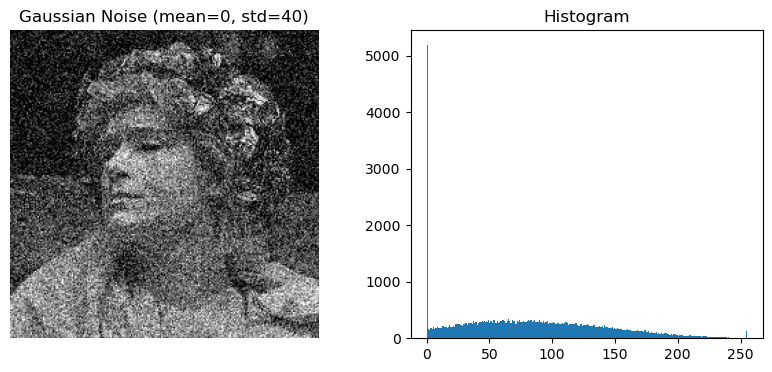

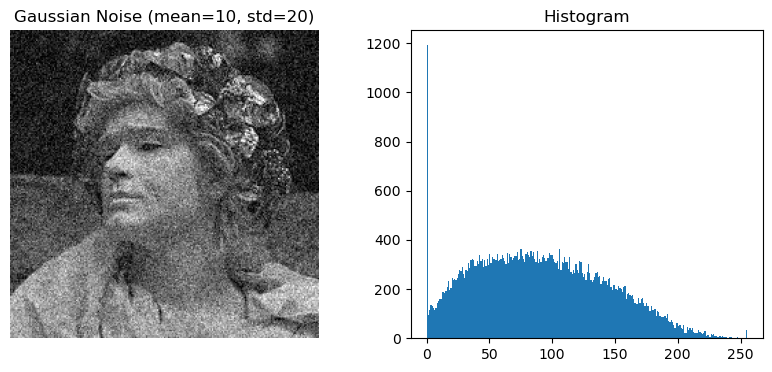

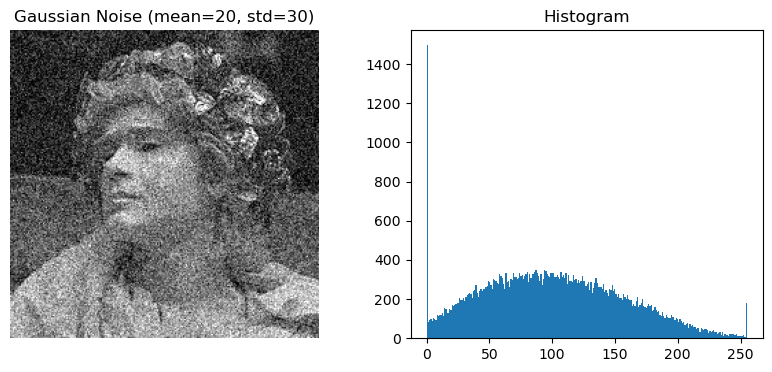

In [24]:
def add_gaussian_noise(image, mean=0, std=20):
    noise = np.random.normal(mean, std, image.shape)
    noisy = image + noise
    noisy = np.clip(noisy, 0, 255)
    return noisy.astype(np.uint8)

params = [(0,10), (0,20), (0,40), (10,20), (20,30)]

for mean, std in params:
    noisy = add_gaussian_noise(image, mean, std)
    show_image_and_hist(noisy, f"Gaussian Noise (mean={mean}, std={std})")

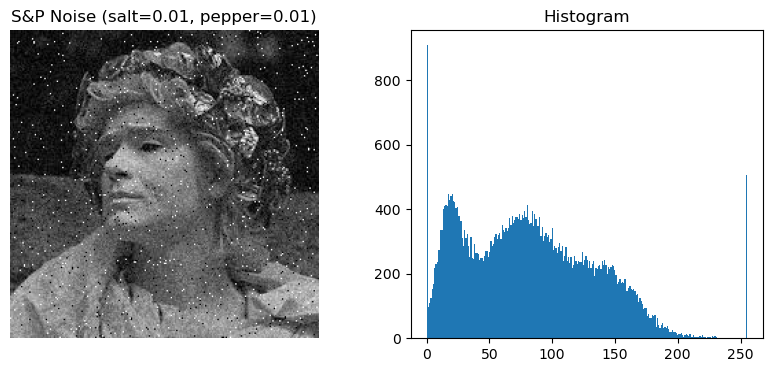

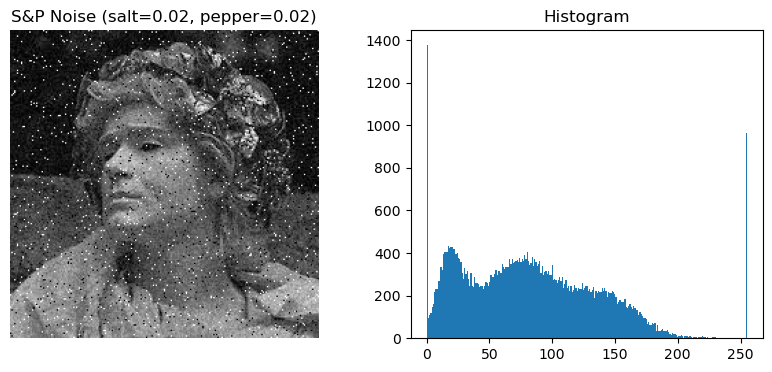

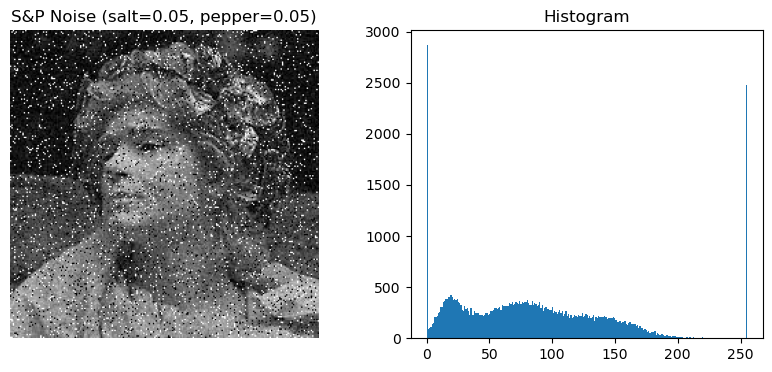

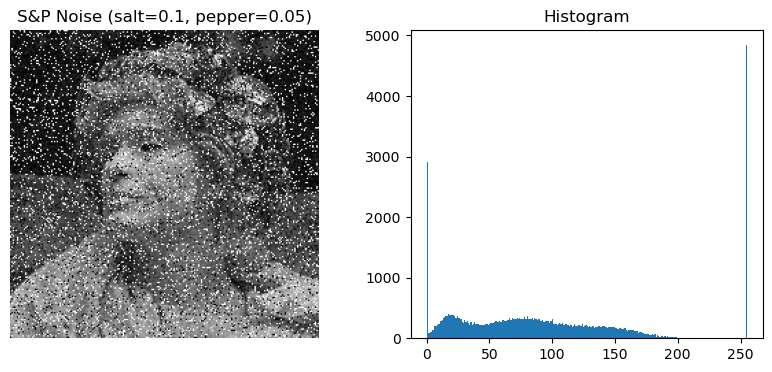

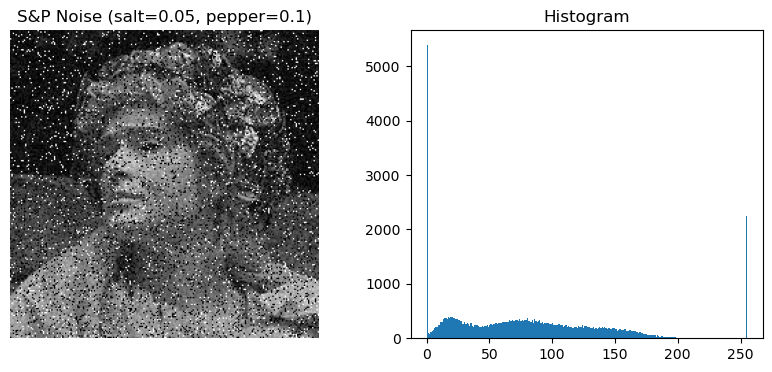

In [30]:
def add_salt_pepper_noise(image, salt_prob, pepper_prob):
    noisy = np.copy(image)
    salt = np.random.rand(*image.shape) < salt_prob
    noisy[salt] = 255
    pepper = np.random.rand(*image.shape) < pepper_prob
    noisy[pepper] = 0
    return noisy

params = [(0.01,0.01), (0.02,0.02), (0.05,0.05), (0.1,0.05), (0.05,0.1)]

for salt, pepper in params:
    noisy = add_salt_pepper_noise(image, salt, pepper)
    show_image_and_hist(noisy, f"S&P Noise (salt={salt}, pepper={pepper})")

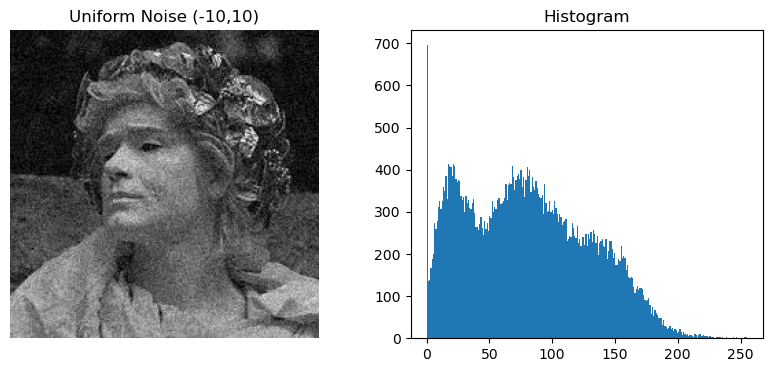

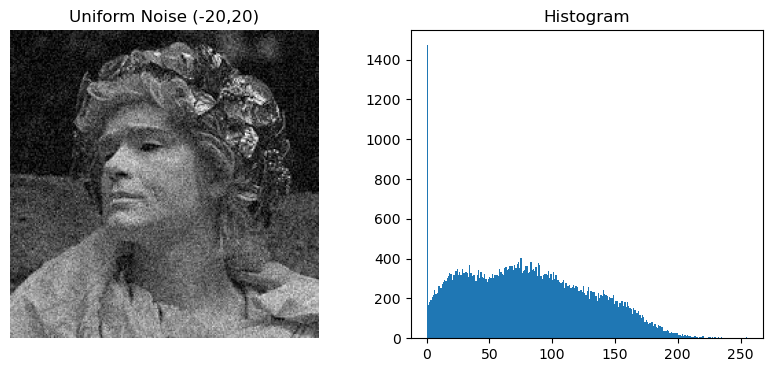

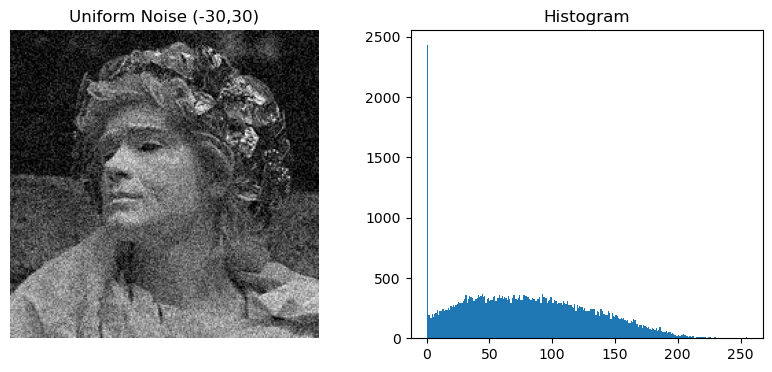

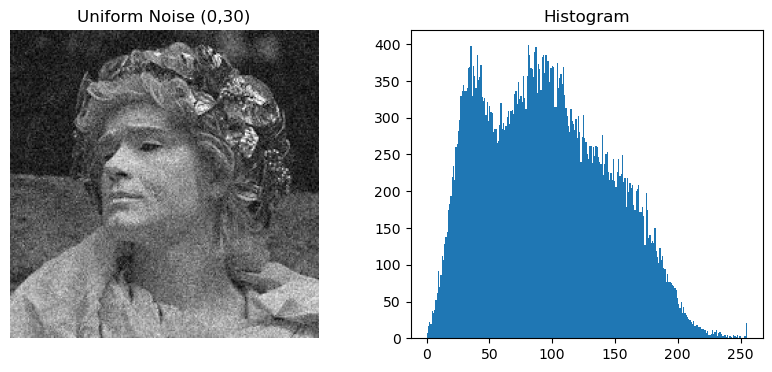

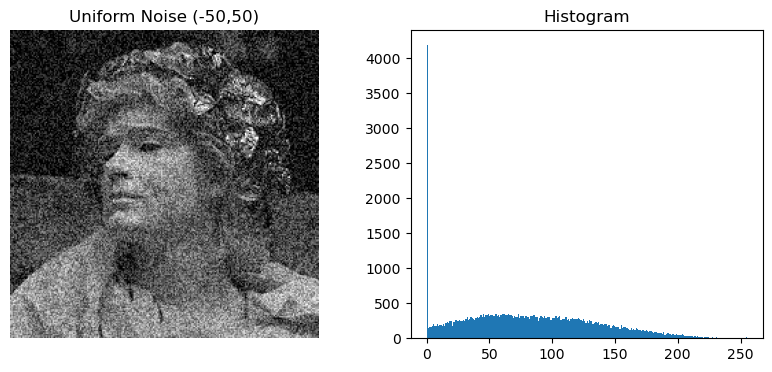

In [31]:
def add_uniform_noise(image, low, high):
    noise = np.random.uniform(low, high, image.shape)
    noisy = image + noise
    noisy = np.clip(noisy, 0, 255)
    return noisy.astype(np.uint8)

params = [(-10,10), (-20,20), (-30,30), (0,30), (-50,50)]

for low, high in params:
    noisy = add_uniform_noise(image, low, high)
    show_image_and_hist(noisy, f"Uniform Noise ({low},{high})")


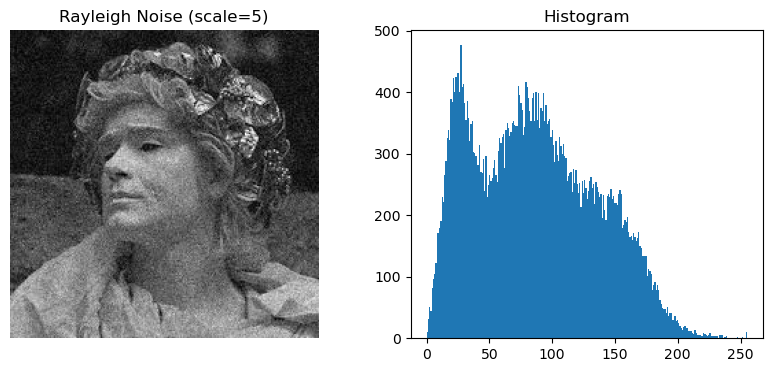

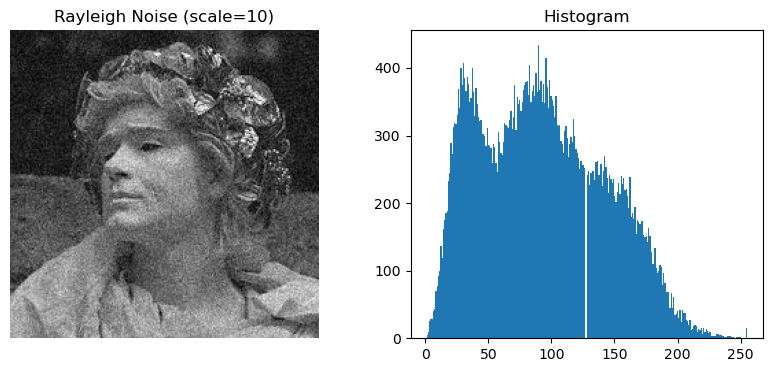

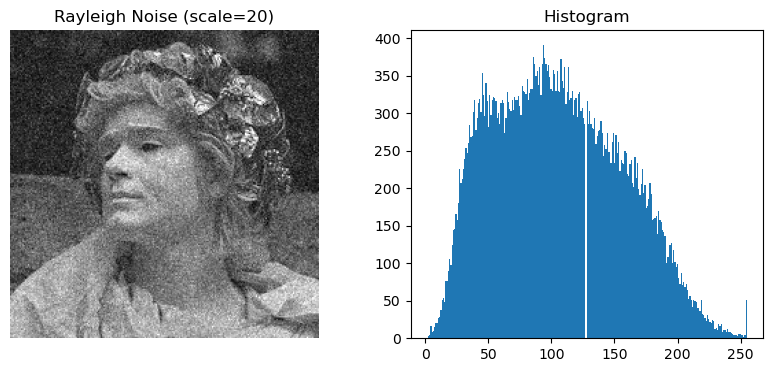

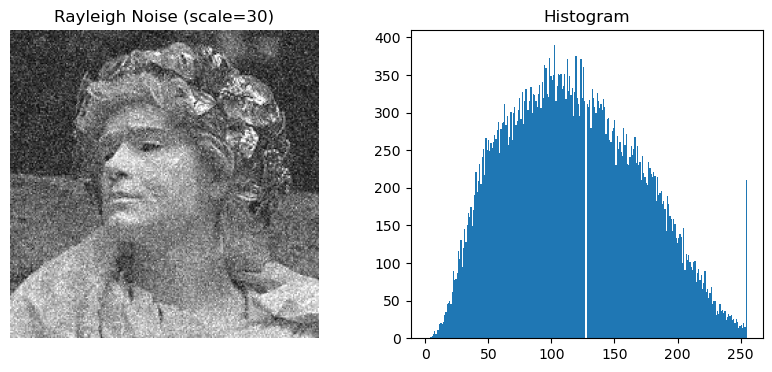

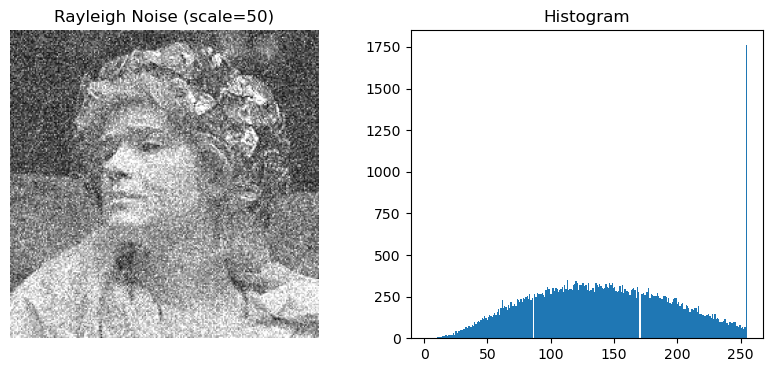

In [29]:
def add_rayleigh_noise(image, scale=20):
    noise = np.random.rayleigh(scale, image.shape)
    noisy = image + noise
    noisy = np.clip(noisy, 0, 255)
    return noisy.astype(np.uint8)

scales = [5, 10, 20, 30, 50]

for s in scales:
    noisy = add_rayleigh_noise(image, s)
    show_image_and_hist(noisy, f"Rayleigh Noise (scale={s})")